# Thuật toán phân cụm BIRCH

## 1. Giới thiệu

Notebook trình bày BIRCH, cài đặt bằng Python theo hướng đối tượng và thực nghiệm
trên dữ liệu khách hàng bán lẻ mô phỏng. Tập lớn có 30.000 khách với hai đặc trưng:
số đơn hàng và tổng chi tiêu trong tháng. Tập 20 điểm dùng để tính CF bằng tay và
theo dõi việc chèn, hấp thụ và tách nút.

Cài đặt sử dụng vector đặc trưng, có thể áp dụng cho dữ liệu nhiều chiều.
Phạm vi thực nghiệm tập trung vào dữ liệu hai chiều. Dữ liệu mô phỏng chỉ phục vụ
minh họa; kết quả chưa xác nhận các phân khúc khách hàng ngoài thực tế.

In [1]:
from pathlib import Path
from dataclasses import dataclass, field
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.preprocessing import StandardScaler

ROOT = Path(".")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "figure.dpi": 100})
SEED, K, B, THRESHOLD = 42, 5, 30, 0.35
FEATURES_2D = ["so_don_hang_thang", "tong_chi_tieu_thang_nghin_vnd"]
SMALL_FEATURES = ["so_don_hang_thang", "so_ngay_tu_lan_mua_cuoi"]

def show_save(fig, filename):
    fig.savefig(OUT / filename, dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)

## 2. CF và CF Tree

Phân cụm là bài toán học không giám sát, nhóm các điểm theo mức tương đồng.
Trong bài này, mỗi khách hàng là một vector đặc trưng và sử dụng khoảng cách
Euclidean. 

### Công thức CF

Một Clustering Feature tóm tắt tập điểm C bằng ba đại lượng:

$$CF=(N,LS,SS),\qquad N=|C|,\quad LS=\sum_{i\in C}x_i,
\quad SS=\sum_{i\in C}\|x_i\|^2.$$

N là số điểm, LS là vector tổng theo từng chiều, SS là một số vô hướng.
Tâm và bán kính được tính bằng:

$$\mu=\frac{LS}{N},\qquad R^2=\frac{SS}{N}-\|\mu\|^2.$$

R là căn trung bình bình phương khoảng cách đến tâm, không phải khoảng cách
lớn nhất. Code dùng `max(R_squared, 0)` để tránh giá trị âm nhỏ do làm tròn.
Hai CF của các tập không giao nhau có thể cộng theo từng thành phần.

### Cách xây cây

CF Tree gồm các nút chứa CF Entry. Entry ở lá đại diện một micro-cluster;
entry ở nút trong lưu CF tóm tắt và liên kết tới nút con.

1. Chọn entry có tâm gần điểm mới nhất, đi từ gốc xuống lá.
2. Cộng thử CF của điểm vào entry gần nhất. Nếu bán kính sau gộp không vượt
   threshold thì hấp thụ; nếu vượt thì tạo entry mới.
3. Khi số entry vượt branching factor, chọn hai tâm xa nhất làm hai seed,
   rồi chia các entry theo seed gần hơn.
4. Cập nhật CF cha. Nếu cha đầy thì tiếp tục tách; gốc đầy thì tạo gốc mới.
5. Lấy CF ở các lá, gom micro-cluster bằng weighted K-Means và gán nhãn.

## 3. Dữ liệu đầu vào

`khach_hang_2d.csv` có 30.000 khách, gồm mã khách và hai đặc trưng số.
`minh_hoa_birch.csv` có 20 điểm, dùng số đơn và số ngày từ lần mua cuối.
Mã khách chỉ để nhận diện bản ghi, không tham gia tính khoảng cách.
Hai đặc trưng không mô tả đầy đủ hành vi mua sắm của khách hàng.

In [2]:
data2 = pd.read_csv(ROOT / "data/khach_hang_2d.csv")
small = pd.read_csv(ROOT / "data/minh_hoa_birch.csv")
print("Dữ liệu khách hàng:", data2.shape, "| Ví dụ minh họa:", small.shape)
display(data2.head())
display(small.head())
display(data2[FEATURES_2D].describe().loc[["mean", "min", "50%", "max"]].round(2))

Dữ liệu khách hàng: (30000, 3) | Ví dụ minh họa: (20, 3)


,ma_khach_hang,so_don_hang_thang,tong_chi_tieu_thang_nghin_vnd
0,A000001,1,322.81
1,A000002,1,247.23
2,A000003,16,7706.56
3,A000004,1,245.59
4,A000005,1,103.97


,ma_khach_hang,so_don_hang_thang,so_ngay_tu_lan_mua_cuoi
0,MH01,1,2
1,MH02,1,4
2,MH03,2,3
3,MH04,2,2
4,MH05,5,8


,so_don_hang_thang,tong_chi_tieu_thang_nghin_vnd
mean,3.62,1789.76
min,0.00,0.00
50%,2.00,593.16
max,50.00,124024.47


In [3]:
def scatter_clusters(X, labels, title, xlabel, ylabel, centers=None, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5))
    for j, label in enumerate(np.unique(labels)):
        mask = labels == label
        ax.scatter(X[mask, 0], X[mask, 1], s=9, alpha=0.45,
                   color=plt.get_cmap("tab10")(j % 10), label=str(label), rasterized=True)
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=75,
                   edgecolors="white", linewidths=0.7, label="Tâm cụm")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend(fontsize=8, title="Nhãn", loc="best")
    return ax

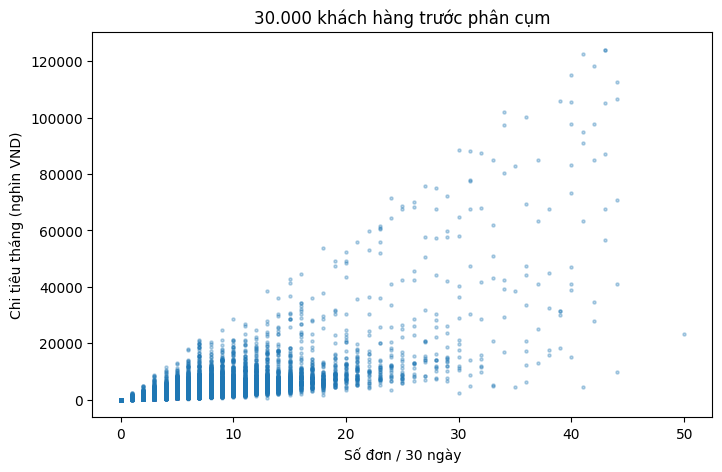

In [4]:
raw2 = data2[FEATURES_2D].to_numpy(float)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(raw2[:, 0], raw2[:, 1], s=5, alpha=0.3)
ax.set(title="30.000 khách hàng trước phân cụm", xlabel="Số đơn / 30 ngày",
       ylabel="Chi tiêu tháng (nghìn VND)")
show_save(fig, "du_lieu_2d_truoc_phan_cum.png")

## 4. Chuẩn hóa dữ liệu

Chi tiêu có thang đo lớn hơn số đơn nên dữ liệu được chuẩn hóa trước khi tính
khoảng cách Euclidean: $z_{ij}=(x_{ij}-\mu_j)/\sigma_j$.
`StandardScaler` tính thống kê theo cột với `ddof=0`; cột hằng dùng hệ số chia 1.
Các mô hình trong bảng so sánh nhận cùng ma trận đã chuẩn hóa.

Chuẩn hóa không loại bỏ tương quan và không bảo đảm dữ liệu có phân phối chuẩn.
Ví dụ 20 điểm giữ giá trị thô để dễ đối chiếu phép tính bằng tay.

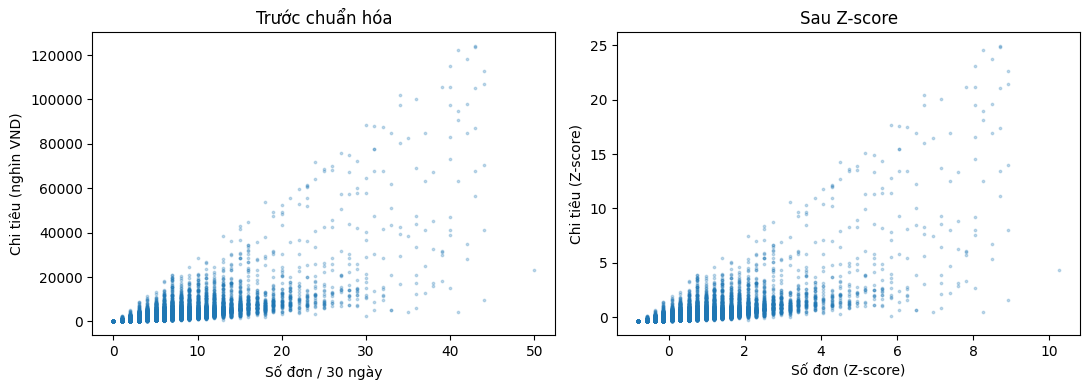

In [5]:
scaler2 = StandardScaler()
X2 = scaler2.fit_transform(raw2)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(raw2[:, 0], raw2[:, 1], s=3, alpha=0.25)
axes[0].set(title="Trước chuẩn hóa", xlabel="Số đơn / 30 ngày", ylabel="Chi tiêu (nghìn VND)")
axes[1].scatter(X2[:, 0], X2[:, 1], s=3, alpha=0.25)
axes[1].set(title="Sau Z-score", xlabel="Số đơn (Z-score)", ylabel="Chi tiêu (Z-score)")
fig.tight_layout()
show_save(fig, "truoc_sau_chuan_hoa.png")

## 5. Cài đặt BIRCH bằng OOP

Phần cài đặt gồm `ClusteringFeature`, `CFEntry`, `CFNode`, `CFTree` và `Birch`.
NumPy được dùng cho phép toán số; phần BIRCH tự viết không gọi thuật toán
phân cụm đóng gói.

- `threshold`: bán kính RMS tối đa của CF lá sau khi thử gộp.
- `branching_factor`: số entry tối đa trong mỗi nút.
- `n_clusters`: số cụm ở bước gom toàn cục; `None` giữ từng micro-cluster.

Phiên bản này xây CF Tree, gom cụm toàn cục và gán nhãn. Các pha tái xây cây
theo giới hạn bộ nhớ và tinh chỉnh của BIRCH nguyên bản chưa được cài đặt.

### CF và cấu trúc nút

`ClusteringFeature` tính N, LS, SS, tâm và bán kính. `CFEntry` chứa một CF
và liên kết con; `CFNode.summary()` cộng các CF để cập nhật thống kê của cha.

In [6]:
def _matrix(X, n_features=None, allow_empty=False):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[1] == 0:
        raise ValueError("X must have shape (n_samples, n_features), n_features > 0")
    if not allow_empty and len(X) == 0:
        raise ValueError("X must contain at least one sample")
    if n_features is not None and X.shape[1] != n_features:
        raise ValueError("Unexpected number of features")
    if not np.isfinite(X).all():
        raise ValueError("X contains NaN or Inf")
    return X


@dataclass
class ClusteringFeature:
    n: int
    ls: np.ndarray
    ss: float

    @classmethod
    def from_points(cls, X):
        X = _matrix(X)
        return cls(len(X), X.sum(axis=0), float(np.sum(X * X)))

    def __add__(self, other):
        if self.ls.shape != other.ls.shape:
            raise ValueError("CF dimensions differ")
        return ClusteringFeature(self.n + other.n, self.ls + other.ls,
                                 self.ss + other.ss)

    @property
    def centroid(self):
        return self.ls / self.n

    @property
    def radius_squared(self):
        center = self.centroid
        return max(float(self.ss / self.n - center @ center), 0.0)

    @property
    def radius(self):
        return float(np.sqrt(self.radius_squared))

    def as_dict(self):
        return {"N": self.n, "LS": self.ls.tolist(), "SS": self.ss,
                "centroid": self.centroid.tolist(), "radius": self.radius}


@dataclass
class CFEntry:
    cf: ClusteringFeature
    child: "CFNode | None" = None


@dataclass
class CFNode:
    is_leaf: bool
    entries: list = field(default_factory=list)

    def summary(self):
        if not self.entries:
            raise ValueError("Empty node has no CF summary")
        total = self.entries[0].cf
        for entry in self.entries[1:]:
            total = total + entry.cf
        return total

### Chèn điểm và tách CF Tree

`_insert` đi theo entry gần nhất và thử hấp thụ ở lá. Nút đầy được tách
bằng `_split`; kết quả tách được trả lên để thay entry cũ bằng hai entry mới.
Mỗi CF cha được tính lại từ các nút con. `validate()` kiểm tra giới hạn
số entry, độ sâu lá, threshold và sự nhất quán của CF.

In [7]:
class CFTree:
    def __init__(self, threshold=0.5, branching_factor=30, record_trace=False):
        if not np.isfinite(threshold) or threshold < 0:
            raise ValueError("threshold must be finite and nonnegative")
        if (isinstance(branching_factor, bool)
                or not isinstance(branching_factor, (int, np.integer))
                or branching_factor < 2):
            raise ValueError("branching_factor must be an integer >= 2")
        self.threshold = float(threshold)
        self.branching_factor = int(branching_factor)
        self.record_trace = record_trace
        self.root = CFNode(is_leaf=True)
        self.n_features = None
        self.history = []
        self.split_counts = {"leaf": 0, "internal": 0, "root": 0}

    def snapshot(self):
        def visit(node):
            return {"is_leaf": node.is_leaf, "entries": [
                {"cf": e.cf.as_dict(),
                 "child": visit(e.child) if e.child is not None else None}
                for e in node.entries]}
        return visit(self.root)

    def insert(self, point):
        point = np.asarray(point, dtype=float)
        if point.ndim != 1 or not len(point) or not np.isfinite(point).all():
            raise ValueError("point must be a finite, nonempty vector")
        if self.n_features is None:
            self.n_features = len(point)
        if len(point) != self.n_features:
            raise ValueError("Unexpected number of features")
        before = self.snapshot() if self.record_trace else None
        events = [] if self.record_trace else None
        cf = ClusteringFeature(1, point.copy(), float(point @ point))
        split = self._insert(self.root, cf, events)
        if split is not None:
            self.root = CFNode(False, [CFEntry(node.summary(), node) for node in split])
            self.split_counts["root"] += 1
            if events is not None:
                events.append({"action": "split_root"})
        if self.record_trace:
            self.history.append({"point": point.tolist(), "before": before,
                                 "events": events, "after": self.snapshot()})

    def _insert(self, node, point_cf, events):
        if not node.entries:
            node.entries.append(CFEntry(point_cf))
            if events is not None:
                events.append({"action": "new_entry", "before_cf": None,
                               "after_cf": point_cf.as_dict(), "candidate_radius": 0.0})
            return None
        centers = np.array([e.cf.centroid for e in node.entries])
        index = int(np.argmin(np.sum((centers - point_cf.centroid) ** 2, axis=1)))
        closest = node.entries[index]
        if node.is_leaf:
            merged = closest.cf + point_cf
            accepted = merged.radius <= self.threshold
            if events is not None:
                events.append({"action": "absorb" if accepted else "new_entry",
                               "before_cf": closest.cf.as_dict(),
                               "after_cf": (merged if accepted else point_cf).as_dict(),
                               "candidate_radius": merged.radius})
            if accepted:
                closest.cf = merged
            else:
                node.entries.append(CFEntry(point_cf))
        else:
            split = self._insert(closest.child, point_cf, events)
            if split is None:
                closest.cf = closest.child.summary()
            else:
                node.entries[index:index + 1] = [CFEntry(n.summary(), n) for n in split]
        if len(node.entries) > self.branching_factor:
            return self._split(node, events)
        return None

    def _split(self, node, events):
        centers = np.array([e.cf.centroid for e in node.entries])
        distances = np.sum((centers[:, None, :] - centers[None, :, :]) ** 2, axis=2)
        # Hai seed xa nhất, cố định mỗi seed vào một phía để tránh nút rỗng khi khoảng cách bằng nhau.
        np.fill_diagonal(distances, -1)
        a, b = np.unravel_index(np.argmax(distances), distances.shape)
        left, right = CFNode(node.is_leaf), CFNode(node.is_leaf)
        for i, entry in enumerate(node.entries):
            if i == a:
                left.entries.append(entry)
            elif i == b:
                right.entries.append(entry)
            elif distances[i, a] <= distances[i, b]:
                left.entries.append(entry)
            else:
                right.entries.append(entry)
        kind = "leaf" if node.is_leaf else "internal"
        self.split_counts[kind] += 1
        if events is not None:
            events.append({"action": "split_" + kind,
                           "seeds": [centers[a].tolist(), centers[b].tolist()],
                           "left_N": left.summary().n, "right_N": right.summary().n})
        return left, right

    def micro_clusters(self):
        result = []
        def visit(node):
            for entry in node.entries:
                if node.is_leaf:
                    result.append(entry.cf)
                else:
                    visit(entry.child)
        visit(self.root)
        return result

    def validate(self):
        """Kiểm tra số entry, độ sâu lá, CF cha và ngưỡng bán kính ở lá."""
        depths = set()
        nodes = 0
        def visit(node, depth):
            nonlocal nodes
            nodes += 1
            assert 1 <= len(node.entries) <= self.branching_factor
            for entry in node.entries:
                assert entry.cf.n >= 1
                if node.is_leaf:
                    assert entry.child is None
                    assert entry.cf.radius <= self.threshold + 1e-7
                    depths.add(depth)
                else:
                    assert entry.child is not None
                    child_cf = visit(entry.child, depth + 1)
                    assert entry.cf.n == child_cf.n
                    np.testing.assert_allclose(entry.cf.ls, child_cf.ls, rtol=1e-10, atol=1e-8)
                    np.testing.assert_allclose(entry.cf.ss, child_cf.ss, rtol=1e-10, atol=1e-8)
            return node.summary()
        total = visit(self.root, 0)
        assert len(depths) == 1
        return {"N": total.n, "nodes": nodes, "height": next(iter(depths)) + 1,
                "micro_clusters": len(self.micro_clusters()), **self.split_counts}

### Khoảng cách và weighted K-Means

Mỗi micro-cluster có tâm $c_i$ và trọng số $N_i$. Bước gom cuối tối thiểu hóa:

$$J=\sum_i N_i\|c_i-v_{g(i)}\|^2.$$

Trọng số N giúp một CF có nhiều khách đóng góp tương ứng vào tâm cụm.
Hàm tự viết dùng khởi tạo k-means++ có trọng số, thử 5 lần và thực hiện tối
đa 100 vòng gán–cập nhật mỗi lần. Phép tính này làm việc trên centroid CF.

In [8]:
def _squared_distances(X, centers):
    return np.maximum(np.sum(X * X, axis=1)[:, None]
                      + np.sum(centers * centers, axis=1)[None, :]
                      - 2 * X @ centers.T, 0.0)


def nearest_centers(X, centers, batch_size=1024):
    """Giới hạn ma trận khoảng cách ở batch_size x số tâm."""
    labels = np.empty(len(X), dtype=int)
    for start in range(0, len(X), batch_size):
        labels[start:start + batch_size] = _squared_distances(
            X[start:start + batch_size], centers).argmin(axis=1)
    return labels


def weighted_kmeans(X, weights, k, random_state=42, n_init=5, max_iter=100):
    """Lloyd trên centroid CF, trọng số N; khởi tạo k-means++ có trọng số."""
    rng = np.random.default_rng(random_state)
    best = None
    for _ in range(n_init):
        chosen = [int(rng.choice(len(X), p=weights / weights.sum()))]
        while len(chosen) < k:
            d2 = _squared_distances(X, X[chosen]).min(axis=1)
            probs = weights * d2
            probs[chosen] = 0
            if probs.sum() <= 1e-15:
                remaining = np.setdiff1d(np.arange(len(X)), chosen)
                chosen.append(int(remaining[0]))
            else:
                chosen.append(int(rng.choice(len(X), p=probs / probs.sum())))
        centers = X[chosen].copy()
        for _ in range(max_iter):
            distances = _squared_distances(X, centers)
            labels = distances.argmin(axis=1)
            updated = centers.copy()
            for j in range(k):
                mask = labels == j
                if mask.any():
                    updated[j] = np.average(X[mask], axis=0, weights=weights[mask])
                else:
                    residual = weights * distances.min(axis=1)
                    updated[j] = X[int(np.argmax(residual))]
            converged = np.allclose(centers, updated, atol=1e-7, rtol=0)
            centers = updated
            if converged:
                break
        distances = _squared_distances(X, centers)
        labels = distances.argmin(axis=1)
        objective = float(np.sum(weights * distances[np.arange(len(X)), labels]))
        if best is None or objective < best[0]:
            best = objective, centers.copy(), labels.copy()
    return best[1], best[2], best[0]

### Lớp Birch

`fit` xây cây, lấy micro-cluster rồi gom thành các cụm cuối. `predict_micro`
tìm centroid CF gần nhất; `predict` tra nhãn toàn cục của CF đó. Việc gán nhãn
được chia theo batch để hạn chế kích thước ma trận khoảng cách trung gian.

In [9]:
class Birch:
    def __init__(self, threshold=0.5, branching_factor=30, n_clusters=5,
                 random_state=42, record_trace=False, compute_labels=True):
        if n_clusters is not None and (isinstance(n_clusters, bool)
                or not isinstance(n_clusters, (int, np.integer)) or n_clusters < 1):
            raise ValueError("n_clusters must be None or a positive integer")
        self.threshold = threshold
        self.branching_factor = branching_factor
        self.n_clusters = n_clusters
        self.random_state = random_state
        self.record_trace = record_trace
        self.compute_labels = compute_labels

    def fit(self, X):
        X = _matrix(X)
        self.n_features_in_ = X.shape[1]
        self.tree_ = CFTree(self.threshold, self.branching_factor, self.record_trace)
        for point in X:
            self.tree_.insert(point)
        self.micro_clusters_ = self.tree_.micro_clusters()
        self.subcluster_centers_ = np.array([cf.centroid for cf in self.micro_clusters_])
        self.subcluster_weights_ = np.array([cf.n for cf in self.micro_clusters_], dtype=float)
        if self.n_clusters is None:
            self.cluster_centers_ = self.subcluster_centers_.copy()
            self.subcluster_labels_ = np.arange(len(self.micro_clusters_))
            self.global_objective_ = 0.0
        else:
            k = min(self.n_clusters, len(self.micro_clusters_))
            (self.cluster_centers_, self.subcluster_labels_,
             self.global_objective_) = weighted_kmeans(
                self.subcluster_centers_, self.subcluster_weights_, k, self.random_state)
        self.n_clusters_ = len(np.unique(self.subcluster_labels_))
        if hasattr(self, "labels_"):
            del self.labels_
        if self.compute_labels:
            self.labels_ = self.predict(X)
        return self

    def predict_micro(self, X):
        if not hasattr(self, "tree_"):
            raise ValueError("Call fit before predict")
        X = _matrix(X, self.n_features_in_, allow_empty=True)
        return nearest_centers(X, self.subcluster_centers_)

    def predict(self, X):
        micro_labels = self.predict_micro(X)
        return self.subcluster_labels_[micro_labels]

    def fit_predict(self, X):
        self.fit(X)
        return self.labels_ if self.compute_labels else self.predict(X)

## 6. Minh họa trên 20 khách hàng

Ví dụ dùng số đơn tháng và số ngày từ lần mua cuối, giữ giá trị thô để tính
tay. Đặt T=1, B=2, K=3.

| Điểm đã chèn | N | LS | SS | Tâm | R² |
|---|---:|---|---:|---|---|
| (1; 2) | 1 | (1; 2) | 5 | (1; 2) | 0 |
| thêm (1; 4) | 2 | (2; 6) | 22 | (1; 3) | 22/2 − 10 = 1 |
| thêm (2; 3) | 3 | (4; 9) | 35 | (4/3; 3) | 35/3 − 97/9 = 8/9 |

Điểm thứ hai được hấp thụ vì R=T=1. Điểm thứ ba cũng được hấp thụ vì
R≈0,9428. Sau khi thêm (2; 2), CF=(4, (6; 11), 43).
Nếu gộp tiếp (5; 8), bán kính mới có R²=7,12 và R≈2,6683>T, nên tạo entry mới.

Ở bước 9, sau khi chèn (9; 3), lá có ba entry trong khi B=2.
Ba tâm A=(1,5; 2,75), B=(5,5; 8,75), C=(9; 3) có khoảng cách bình phương
d²(A,B)=52; d²(A,C)=56,3125; d²(B,C)=45,3125. Chọn A và C làm seed,
đưa B về phía C. Hai lá mới có N=4 và N=5; gốc mới giữ tổng N=9.

Code sau đối chiếu CF bằng `assert` và ghi lại từng lần chèn. Các hình cây
được dựng từ trạng thái `before` và `after` trong lịch sử thực thi.

In [10]:
small_X = small[SMALL_FEATURES].to_numpy(float)
small_model = Birch(threshold=1, branching_factor=2, n_clusters=3,
                    random_state=SEED, record_trace=True).fit(small_X)
manual_cf = ClusteringFeature.from_points(small_X[:3])
assert manual_cf.n == 3 and manual_cf.ss == 35
np.testing.assert_allclose(manual_cf.ls, [4, 9])
np.testing.assert_allclose(manual_cf.radius_squared, 8 / 9)
display(pd.DataFrame([ClusteringFeature.from_points(small_X[:i]).as_dict() for i in [1, 2, 3, 4]]))
assert small_model.tree_.history[4]["events"][0]["candidate_radius"] > 1
trace_rows = []
for step, record in enumerate(small_model.tree_.history, 1):
    event = record["events"][0]
    trace_rows.append({"step": step, "point": record["point"],
                       "decision": event["action"], "candidate_radius": event["candidate_radius"],
                       "CF_before": event["before_cf"], "CF_after": event["after_cf"],
                       "split_events": [e["action"] for e in record["events"][1:]]})
trace_table = pd.DataFrame(trace_rows)
with pd.option_context("display.max_colwidth", 160):
    display(trace_table)
small_stats = small_model.tree_.validate()
assert small_stats["leaf"] >= 1 and small_stats["internal"] >= 1 and small_stats["root"] >= 1
display(small_stats)

,N,LS,SS,centroid,radius
0,1,"[1.0, 2.0]",5.0,"[1.0, 2.0]",0.000000
1,2,"[2.0, 6.0]",22.0,"[1.0, 3.0]",1.000000
2,3,"[4.0, 9.0]",35.0,"[1.3333333333333333, 3.0]",0.942809
3,4,"[6.0, 11.0]",43.0,"[1.5, 2.75]",0.968246


,step,point,decision,candidate_radius,CF_before,CF_after,split_events
0,1,"[1.0, 2.0]",new_entry,0.000000,None,"{'N': 1, 'LS': [1.0, 2.0], 'SS': 5.0, 'centroid': [1.0, 2.0], 'radius': 0.0}",[]
1,2,"[1.0, 4.0]",absorb,1.000000,"{'N': 1, 'LS': [1.0, 2.0], 'SS': 5.0, 'centroid': [1.0, 2.0], 'radius': 0.0}","{'N': 2, 'LS': [2.0, 6.0], 'SS': 22.0, 'centroid': [1.0, 3.0], 'radius': 1.0}",[]
2,3,"[2.0, 3.0]",absorb,0.942809,"{'N': 2, 'LS': [2.0, 6.0], 'SS': 22.0, 'centroid': [1.0, 3.0], 'radius': 1.0}","{'N': 3, 'LS': [4.0, 9.0], 'SS': 35.0, 'centroid': [1.3333333333333333, 3.0], 'radius': 0.9428090415820626}",[]
3,4,"[2.0, 2.0]",absorb,0.968246,"{'N': 3, 'LS': [4.0, 9.0], 'SS': 35.0, 'centroid': [1.3333333333333333, 3.0], 'radius': 0.9428090415820626}","{'N': 4, 'LS': [6.0, 11.0], 'SS': 43.0, 'centroid': [1.5, 2.75], 'radius': 0.9682458365518543}",[]
4,5,"[5.0, 8.0]",new_entry,2.668333,"{'N': 4, 'LS': [6.0, 11.0], 'SS': 43.0, 'centroid': [1.5, 2.75], 'radius': 0.9682458365518543}","{'N': 1, 'LS': [5.0, 8.0], 'SS': 89.0, 'centroid': [5.0, 8.0], 'radius': 0.0}",[]
5,6,"[5.0, 10.0]",absorb,1.000000,"{'N': 1, 'LS': [5.0, 8.0], 'SS': 89.0, 'centroid': [5.0, 8.0], 'radius': 0.0}","{'N': 2, 'LS': [10.0, 18.0], 'SS': 214.0, 'centroid': [5.0, 9.0], 'radius': 1.0}",[]
6,7,"[6.0, 9.0]",absorb,0.942809,"{'N': 2, 'LS': [10.0, 18.0], 'SS': 214.0, 'centroid': [5.0, 9.0], 'radius': 1.0}","{'N': 3, 'LS': [16.0, 27.0], 'SS': 331.0, 'centroid': [5.333333333333333, 9.0], 'radius': 0.9428090415820617}",[]
7,8,"[6.0, 8.0]",absorb,0.968246,"{'N': 3, 'LS': [16.0, 27.0], 'SS': 331.0, 'centroid': [5.333333333333333, 9.0], 'radius': 0.9428090415820617}","{'N': 4, 'LS': [22.0, 35.0], 'SS': 431.0, 'centroid': [5.5, 8.75], 'radius': 0.9682458365518543}",[]
8,9,"[9.0, 3.0]",new_entry,2.828427,"{'N': 4, 'LS': [22.0, 35.0], 'SS': 431.0, 'centroid': [5.5, 8.75], 'radius': 0.9682458365518543}","{'N': 1, 'LS': [9.0, 3.0], 'SS': 90.0, 'centroid': [9.0, 3.0], 'radius': 0.0}","[split_leaf, split_root]"
9,10,"[9.0, 5.0]",absorb,1.000000,"{'N': 1, 'LS': [9.0, 3.0], 'SS': 90.0, 'centroid': [9.0, 3.0], 'radius': 0.0}","{'N': 2, 'LS': [18.0, 8.0], 'SS': 196.0, 'centroid': [9.0, 4.0], 'radius': 1.0}",[]


{'N': 20,
 'nodes': 6,
 'height': 3,
 'micro_clusters': 5,
 'leaf': 2,
 'internal': 1,
 'root': 2}

In [11]:
def plot_tree(snapshot, title):
    positions, links, labels = {}, [], {}
    next_x = [0]
    def visit(node, depth, name):
        children = [(i, e["child"]) for i, e in enumerate(node["entries"]) if e["child"]]
        child_x = []
        for i, child in children:
            child_name = f"{name}.{i}"
            child_x.append(visit(child, depth + 1, child_name))
            links.append((name, child_name))
        x = float(np.mean(child_x)) if child_x else float(next_x[0])
        if not child_x:
            next_x[0] += 1
        positions[name] = (x, -depth)
        kind = "Lá" if node["is_leaf"] else "Trong"
        entry_text = [f"E{i}: N={e['cf']['N']}, μ={np.round(e['cf']['centroid'], 1)}"
                      for i, e in enumerate(node["entries"])]
        labels[name] = kind + "\n" + "\n".join(entry_text)
        return x
    visit(snapshot, 0, "R")
    fig, ax = plt.subplots(figsize=(max(8, next_x[0] * 2.8), 4.8))
    for parent, child in links:
        px, py = positions[parent]
        cx, cy = positions[child]
        ax.plot([px, cx], [py, cy], color="0.65", zorder=0)
    for name, (x, y) in positions.items():
        ax.text(x, y, labels[name], ha="center", va="center", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.5", facecolor="#eef3f7", edgecolor="0.4"))
    ax.set_xlim(-0.7, max(0.7, next_x[0] - 0.3))
    ax.set_ylim(min(y for _, y in positions.values()) - 0.6, 0.6)
    ax.set_title(title)
    ax.axis("off")
    return fig

**Bước 9, chèn [9.0, 3.0], sự kiện split_leaf.**

[{'action': 'new_entry',
  'before_cf': {'N': 4,
   'LS': [22.0, 35.0],
   'SS': 431.0,
   'centroid': [5.5, 8.75],
   'radius': 0.9682458365518543},
  'after_cf': {'N': 1,
   'LS': [9.0, 3.0],
   'SS': 90.0,
   'centroid': [9.0, 3.0],
   'radius': 0.0},
  'candidate_radius': 2.8284271247461903},
 {'action': 'split_leaf',
  'seeds': [[1.5, 2.75], [9.0, 3.0]],
  'left_N': 4,
  'right_N': 5},
 {'action': 'split_root'}]

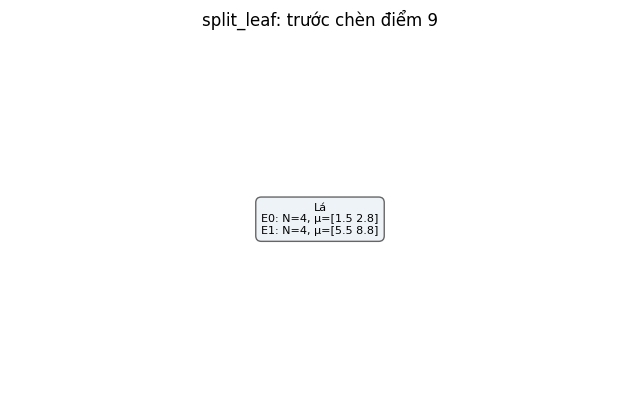

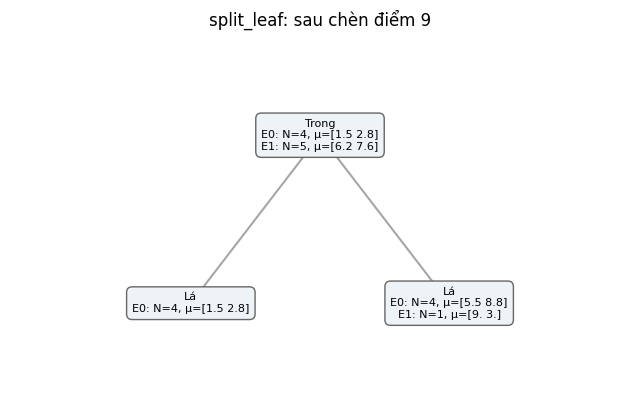

**Bước 13, chèn [13.0, 10.0], sự kiện split_internal.**

[{'action': 'new_entry',
  'before_cf': {'N': 4,
   'LS': [38.0, 15.0],
   'SS': 421.0,
   'centroid': [9.5, 3.75],
   'radius': 0.9682458365518543},
  'after_cf': {'N': 1,
   'LS': [13.0, 10.0],
   'SS': 269.0,
   'centroid': [13.0, 10.0],
   'radius': 0.0},
  'candidate_radius': 2.993325909419154},
 {'action': 'split_leaf',
  'seeds': [[5.5, 8.75], [13.0, 10.0]],
  'left_N': 8,
  'right_N': 1},
 {'action': 'split_internal',
  'seeds': [[1.5, 2.75], [13.0, 10.0]],
  'left_N': 4,
  'right_N': 9},
 {'action': 'split_root'}]

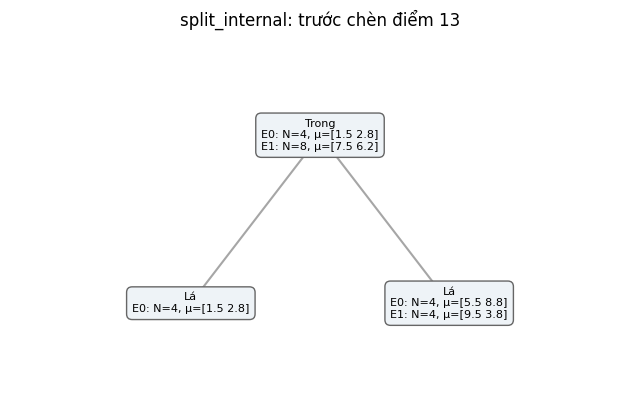

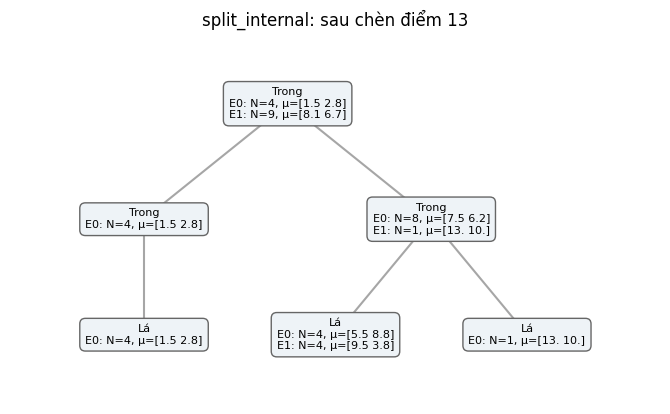

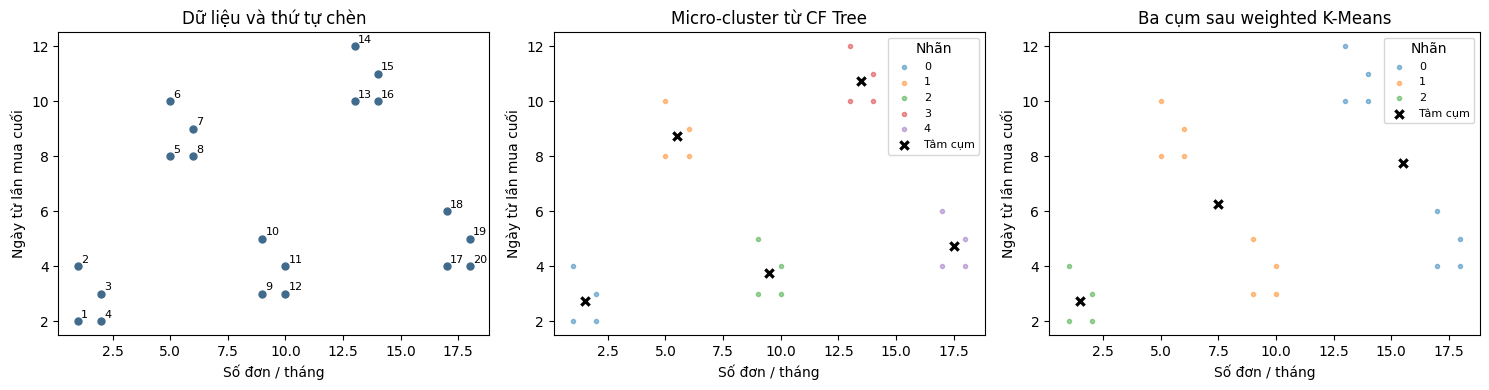

In [12]:
for split_kind in ["split_leaf", "split_internal"]:
    index, record = next((i, h) for i, h in enumerate(small_model.tree_.history)
                         if any(e["action"] == split_kind for e in h["events"]))
    display(Markdown(f"**Bước {index + 1}, chèn {record['point']}, sự kiện {split_kind}.**"))
    display(record["events"])
    for state in ["before", "after"]:
        title = f"{split_kind}: {'trước' if state == 'before' else 'sau'} chèn điểm {index + 1}"
        show_save(plot_tree(record[state], title), f"{split_kind}_{state}.png")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(small_X[:, 0], small_X[:, 1], color="#406b8c", s=25)
for i, point in enumerate(small_X):
    axes[0].annotate(str(i + 1), point + 0.13, fontsize=8)
axes[0].set(title="Dữ liệu và thứ tự chèn", xlabel="Số đơn / tháng", ylabel="Ngày từ lần mua cuối")
scatter_clusters(small_X, small_model.predict_micro(small_X), "Micro-cluster từ CF Tree",
                 "Số đơn / tháng", "Ngày từ lần mua cuối", small_model.subcluster_centers_, axes[1])
scatter_clusters(small_X, small_model.labels_, "Ba cụm sau weighted K-Means",
                 "Số đơn / tháng", "Ngày từ lần mua cuối", small_model.cluster_centers_, axes[2])
fig.tight_layout()
show_save(fig, "minh_hoa_20_khach_hang.png")

## 7. Phân cụm 30.000 khách hàng

Chạy trên X2 với threshold=0,35, branching_factor=30 và n_clusters=5.
K=5 là số cụm đặt trước để minh họa; chưa thực hiện tìm số cụm phù hợp nhất.
Màu biểu thị nhãn dự đoán. Tâm và thống kê từng cụm được đưa về đơn vị gốc để đọc.
Mã cụm chỉ là ký hiệu, không thể hiện thứ hạng khách hàng.

{'N': 30000,
 'nodes': 9,
 'height': 2,
 'micro_clusters': 175,
 'leaf': 7,
 'internal': 0,
 'root': 1}

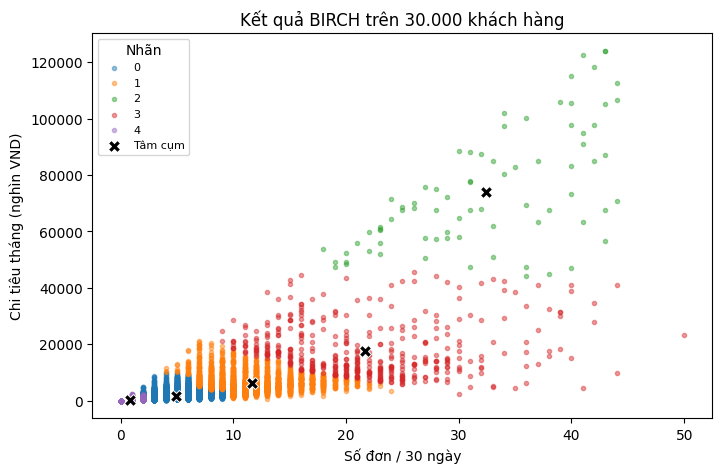

so_don_hang_thang               tong_chi_tieu_thang_nghin_vnd  \
                     size   mean median                          size   
cluster                                                                 
0                   10603   4.79    4.0                         10603   
1                    2767  11.53   11.0                          2767   
2                      77  32.42   32.0                            77   
3                     448  21.54   21.0                           448   
4                   16105   0.85    1.0                         16105   

                             
             mean    median  
cluster                      
0         1789.19   1420.52  
1         6183.22   5630.88  
2        74101.11  68178.76  
3        17593.35  15037.94  
4          249.95    195.65

In [13]:
model2 = Birch(THRESHOLD, B, K, SEED).fit(X2)
stats2 = model2.tree_.validate()
display(stats2)
fig, ax = plt.subplots(figsize=(8, 5))
scatter_clusters(raw2, model2.labels_, "Kết quả BIRCH trên 30.000 khách hàng",
                 "Số đơn / 30 ngày", "Chi tiêu tháng (nghìn VND)",
                 scaler2.inverse_transform(model2.cluster_centers_), ax)
show_save(fig, "phan_cum_2d.png")
profile2 = (
    data2[FEATURES_2D]
    .assign(cluster=model2.labels_)
    .groupby("cluster")
    .agg(["size", "mean", "median"])
)
display(profile2.round(2))
profile2.to_csv(OUT / "thong_ke_cum_2d.csv")

## 8. So sánh với thư viện và K-Means

Lấy cố định 3.000 điểm từ X2 để chạy BIRCH tự viết, BIRCH của scikit-learn và
K-Means. Hai bản BIRCH nhận cùng threshold, branching factor, K và thứ tự điểm.
Bản tự viết gom CF bằng weighted K-Means; bản thư viện dùng Agglomerative khi K
là số nguyên, nên không yêu cầu hai kết quả trùng nhau.

Thời gian tính từ lúc fit đến khi lấy được nhãn, đo một lần và giới hạn một thread.
Đọc CSV, chuẩn hóa, vẽ và tính Silhouette nằm ngoài phép đo. Thời gian có thể dao
động giữa các lần chạy. Bảng này dùng 3.000 điểm, khác lần minh họa 30.000 điểm ở trên.

Silhouette có $s=(b-a)/\max(a,b)$: a là khoảng cách trung bình tới các điểm cùng
cụm, b là khoảng cách trung bình nhỏ nhất tới một cụm khác. Dùng chung mẫu cố định
tối đa 1.200 điểm cho ba mô hình. Chỉ số không được tính nếu mẫu không có ít nhất
hai cụm hợp lệ. Silhouette cao vẫn cần đối chiếu hình và phân bố kích thước cụm.

Về nguyên lý, K-Means cập nhật trực tiếp K tâm; Agglomerative gộp dần các cụm;
DBSCAN tìm vùng mật độ và có thể đánh dấu nhiễu. BIRCH xây CF Tree để tóm tắt
dữ liệu trước bước gom cụm cuối. Trong phần thực nghiệm này chỉ chạy ba mô hình nêu trên.

,algorithm,n_samples,seconds,n_clusters,n_micro_clusters,largest_cluster_fraction,Silhouette
0,BIRCH tự viết,3000,0.2239,5,54.0,0.5437,0.5752
1,BIRCH sklearn,3000,2.2296,5,54.0,0.9647,0.7077
2,K-Means,3000,0.0197,5,NaN,0.6373,0.5981


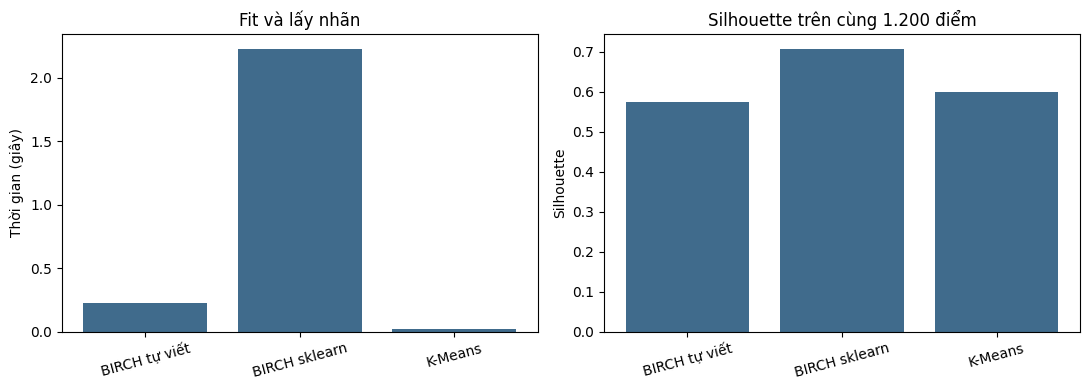

In [14]:
from sklearn.cluster import Birch as SklearnBirch, KMeans
from sklearn.metrics import silhouette_score

chosen = np.sort(
    np.random.default_rng(SEED).choice(len(X2), 3000, replace=False)
)
X_bench = X2[chosen]
sample_indices = np.sort(
    np.random.default_rng(SEED).choice(len(X_bench), 1200, replace=False)
)
estimators = [
    ("BIRCH tự viết", Birch(THRESHOLD, B, K, SEED, compute_labels=False)),
    ("BIRCH sklearn", SklearnBirch(threshold=THRESHOLD, branching_factor=B,
                                  n_clusters=K, compute_labels=False)),
    ("K-Means", KMeans(n_clusters=K, n_init=10, random_state=SEED))]
rows = []
with threadpool_limits(limits=1):
    for name, estimator in estimators:
        start = perf_counter()
        estimator.fit(X_bench)
        labels = (estimator.labels_.copy()
                  if hasattr(estimator, "labels_")
                  else estimator.predict(X_bench))
        seconds = perf_counter() - start
        sampled_labels = labels[sample_indices]
        score = np.nan
        if 2 <= len(np.unique(sampled_labels)) < len(sampled_labels):
            score = silhouette_score(X_bench[sample_indices], sampled_labels)
        counts = np.unique(labels, return_counts=True)[1]
        micro_count = (len(estimator.subcluster_centers_)
                       if hasattr(estimator, "subcluster_centers_")
                       else np.nan)
        rows.append({"algorithm": name, "n_samples": len(X_bench),
                     "seconds": seconds,
                     "n_clusters": len(counts),
                     "n_micro_clusters": micro_count,
                     "largest_cluster_fraction": counts.max() / len(labels),
                     "Silhouette": score})
results = pd.DataFrame(rows)
display(results.round(4))
results.to_csv(OUT / "benchmark_2d.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(results.algorithm, results.seconds, color="#406b8c")
axes[0].set(title="Fit và lấy nhãn", ylabel="Thời gian (giây)")
axes[1].bar(results.algorithm, results.Silhouette, color="#406b8c")
axes[1].set(title="Silhouette trên cùng 1.200 điểm", ylabel="Silhouette")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=15)
fig.tight_layout()
show_save(fig, "benchmark_2d.png")

## 9. Nhận xét và kết luận

CF Tree tóm tắt dữ liệu thành các micro-cluster, giúp giảm số đối tượng ở bước
gom cụm cuối. Cài đặt đã xử lý hấp thụ điểm, tách lá, nút trong và gốc; ví dụ nhỏ
đối chiếu được với phép tính tay. Code dùng vector nên không cố định số chiều,
nhưng các thực nghiệm trong bài chỉ dùng hai chiều.

BIRCH nhạy với thang đo, threshold và thứ tự chèn. CF chỉ giữ thống kê tổng hợp,
không giữ đầy đủ hình dạng của dữ liệu. Bản tự viết gán nhãn bằng cách tìm tâm CF
gần nhất, nên chi phí tăng theo số điểm và số micro-cluster.

Dữ liệu là mô phỏng; hai đặc trưng chưa đủ mô tả toàn bộ hành vi mua sắm.
Tham số được đặt cố định, chưa tối ưu cho từng phương pháp. Thời gian đo một lần
chỉ phản ánh lần chạy hiện tại. Chưa cài tái xây cây theo giới hạn bộ nhớ và pha
tinh chỉnh của BIRCH nguyên bản; chưa đo bộ nhớ thực thi.

Tài liệu: [BIRCH, Zhang và cộng sự (1996)](https://www.cse.ust.hk/~raywong/comp5331/References/BIRCHAnEfficientDataClusteringMethodForVeryLargeDatabases.pdf);
[StandardScaler](https://scikit-learn.org/1.9/modules/generated/sklearn.preprocessing.StandardScaler.html);
[Silhouette](https://scikit-learn.org/1.9/modules/generated/sklearn.metrics.silhouette_score.html);
[Birch của scikit-learn](https://scikit-learn.org/1.9/modules/generated/sklearn.cluster.Birch.html).
